# Main Topic - Driveability

### Sriram Schelbert
Pitt Email: sas547@pitt.edu

### Links
https://data.wprdc.org/dataset/allegheny-county-crash-data

https://data.wprdc.org/dataset/neighborhoods2

## Introduction
In this project our group is ranking the various neighborhoods of Pittsburgh by their driveability, using the police crash reports, roadwork requests, traffic permits, and injury reports from various datasets. This notebook uses police report data to determine the amount and severity of crashes adnd uses the neighborhoods GeoJson to organize the data via neighborhood.

True
7019
(90, 41)
0


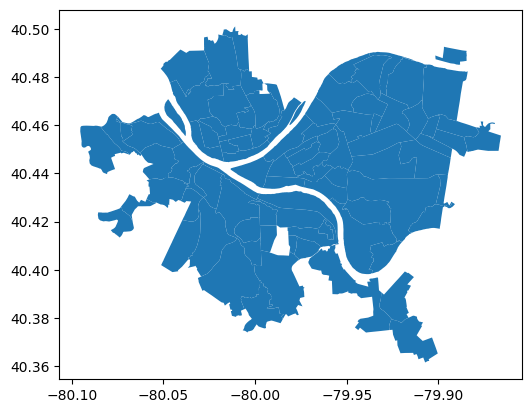

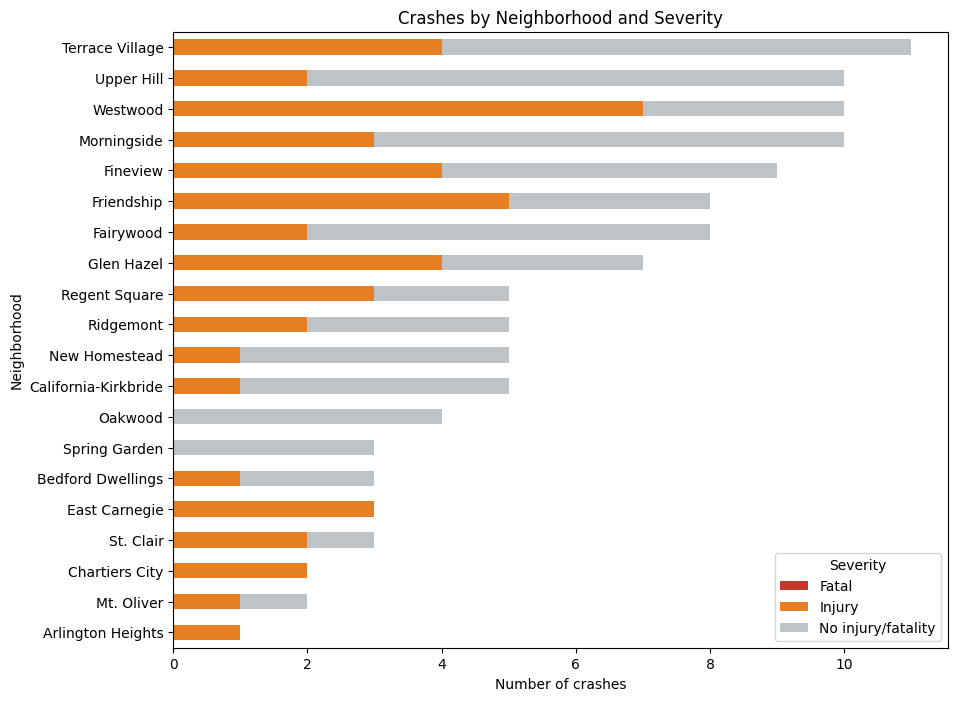

In [5]:
import json
import pandas as pd
import geopandas as gpd
from shapely import wkb

# Load the datastore export
with open("geodata.json", "r", encoding="utf-8") as f:
    data = json.load(f)

columns = [fld["id"] for fld in data["fields"]]
records = pd.DataFrame(data["records"], columns=columns)

# Strip the leading "\x" and decode the hex WKB into shapely geometries
def parse_wkb(s):
    if s is None:
        return None
    if s.startswith("\\x"):
        s = s[2:]
    return wkb.loads(s, hex=True)

records["geometry"] = records["dataspatial_wkb"].apply(parse_wkb)

neighborhoods = gpd.GeoDataFrame(
    records.drop(columns=["dataspatial_wkb"]),
    geometry="geometry",
    crs="EPSG:4326",   # the coordinates (~ -79.9, 40.4) are already lat/lon
)

# Crashes
crash = pd.read_csv("crash_allegheny_2025.csv")
crash = crash.dropna(subset=["DEC_LONGITUDE", "DEC_LATITUDE"])

crashes_gdf = gpd.GeoDataFrame(
    crash,
    geometry=gpd.points_from_xy(crash["DEC_LONGITUDE"], crash["DEC_LATITUDE"]),
    crs="EPSG:4326",
)

# Spatial join with geojson and latitude and longitude from csv
joined = gpd.sjoin(
    crashes_gdf,
    neighborhoods[["hood", "geometry"]],
    how="left",
    predicate="within",
)

joined = joined.rename(columns={"hood": "neighborhood"}).drop(columns=["geometry", "index_right"])

print(len(joined) == len(crashes_gdf))      # Should be True if no duplicate matches
print(joined["neighborhood"].isna().sum())  # Crashes outside the city polygons
joined.to_csv("crashes_with_neighborhoods.csv", index=False)

print(neighborhoods.shape)
print(neighborhoods.geometry.isna().sum())
neighborhoods.plot()

# Making a new column to describe the severity of the crashes
# Severity category for each crash (later lines overwrite earlier ones)
joined["severity"] = "No injury/fatality"
joined.loc[joined["INJURY_COUNT"] > 0, "severity"] = "Injury"
joined.loc[joined["FATAL_COUNT"] > 0, "severity"] = "Fatal"   # use your actual column name

# Rows = neighborhoods, columns = severity, values = number of crashes
stacked = pd.crosstab(joined["neighborhood"], joined["severity"])

# Fix stacking order, then sort neighborhoods by total crashes
stacked = stacked[["Fatal", "Injury", "No injury/fatality"]]
stacked = stacked.loc[stacked.sum(axis=1).sort_values(ascending=False).index]

ax = stacked.tail(20).plot.barh(
    stacked=True,
    figsize=(10, 8),
    color=["#c0392b", "#e67e22", "#bdc3c7"],   # fatal, injury, none
    title="Crashes by Neighborhood and Severity",
    xlabel="Number of crashes",
    ylabel="Neighborhood",
)
ax.invert_yaxis()   # largest at the top
ax.legend(title="Severity")


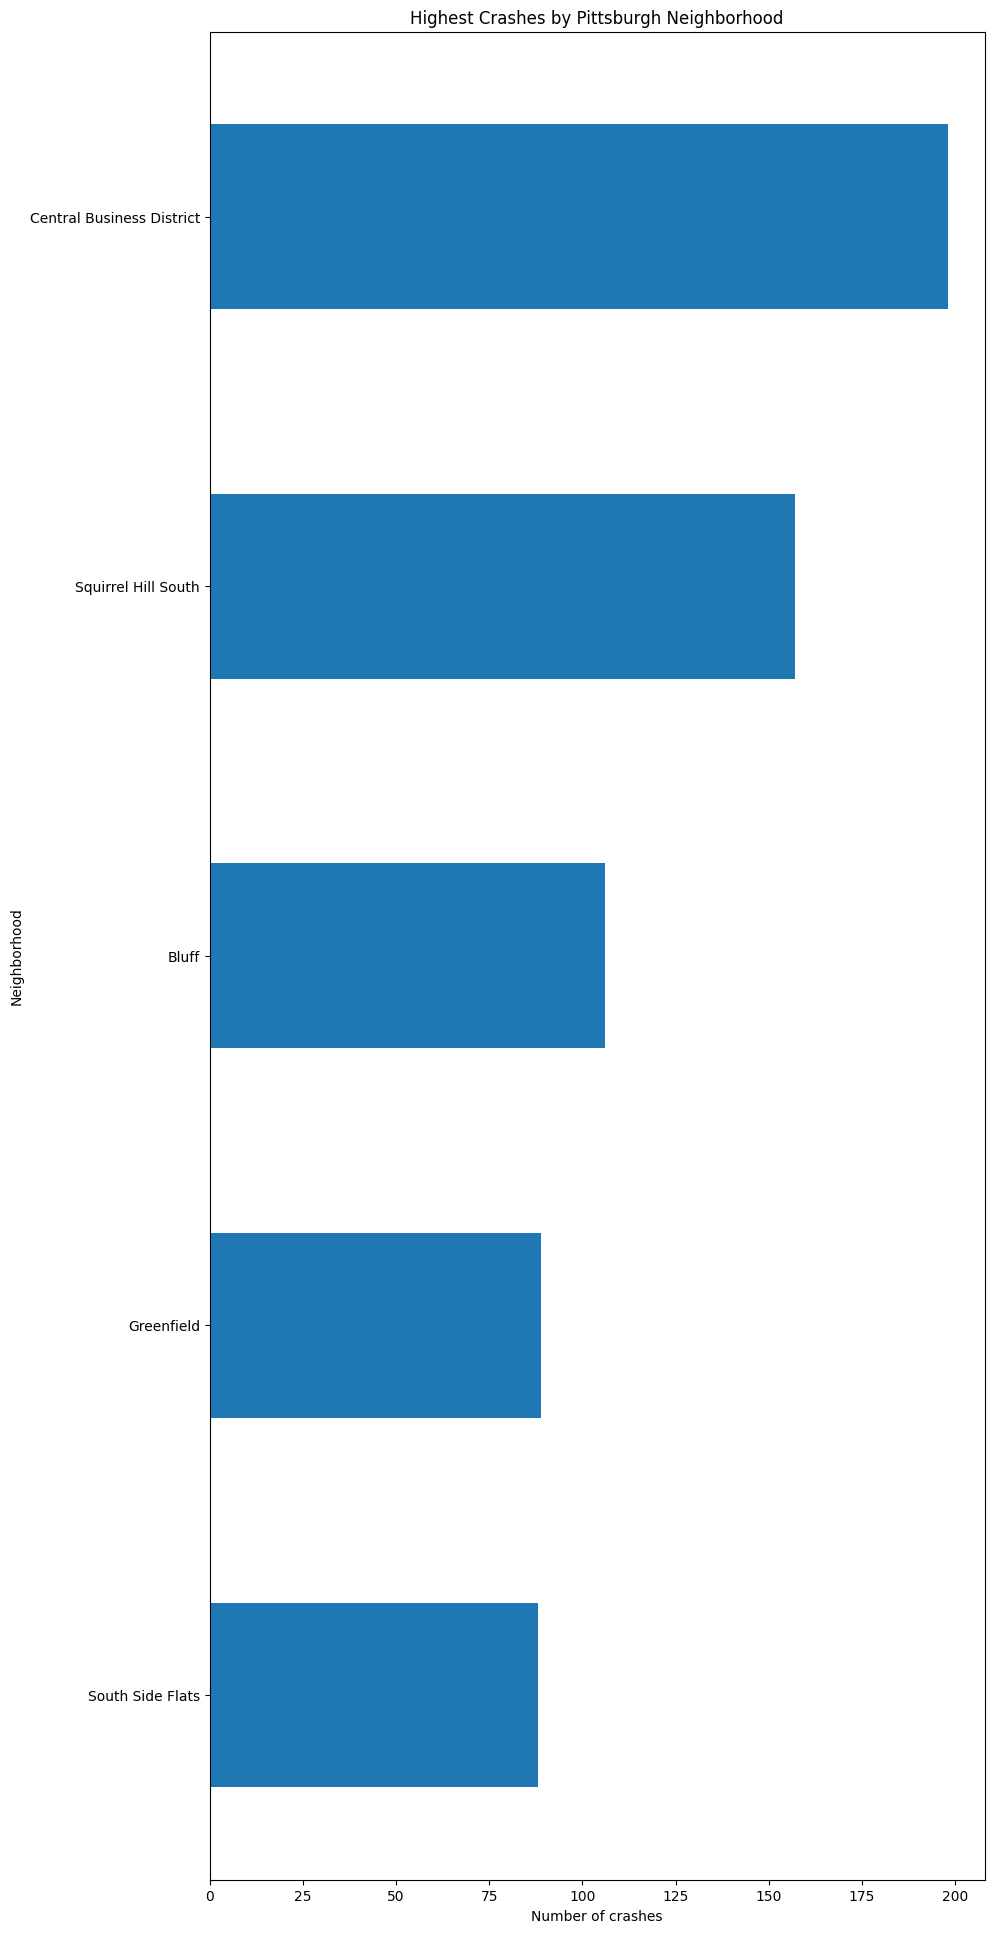

In [16]:
# joined["neighborhood"].value_counts().head(5).plot.barh(
#     figsize=(10, 24),
#     title="Highest Crashes by Pittsburgh Neighborhood",
#     xlabel="Number of crashes",
#     ylabel="Neighborhood",
# ).invert_yaxis()

<Axes: title={'center': 'Lowest Crashes by Pittsburgh Neighborhood'}, xlabel='Number of crashes', ylabel='Neighborhood'>

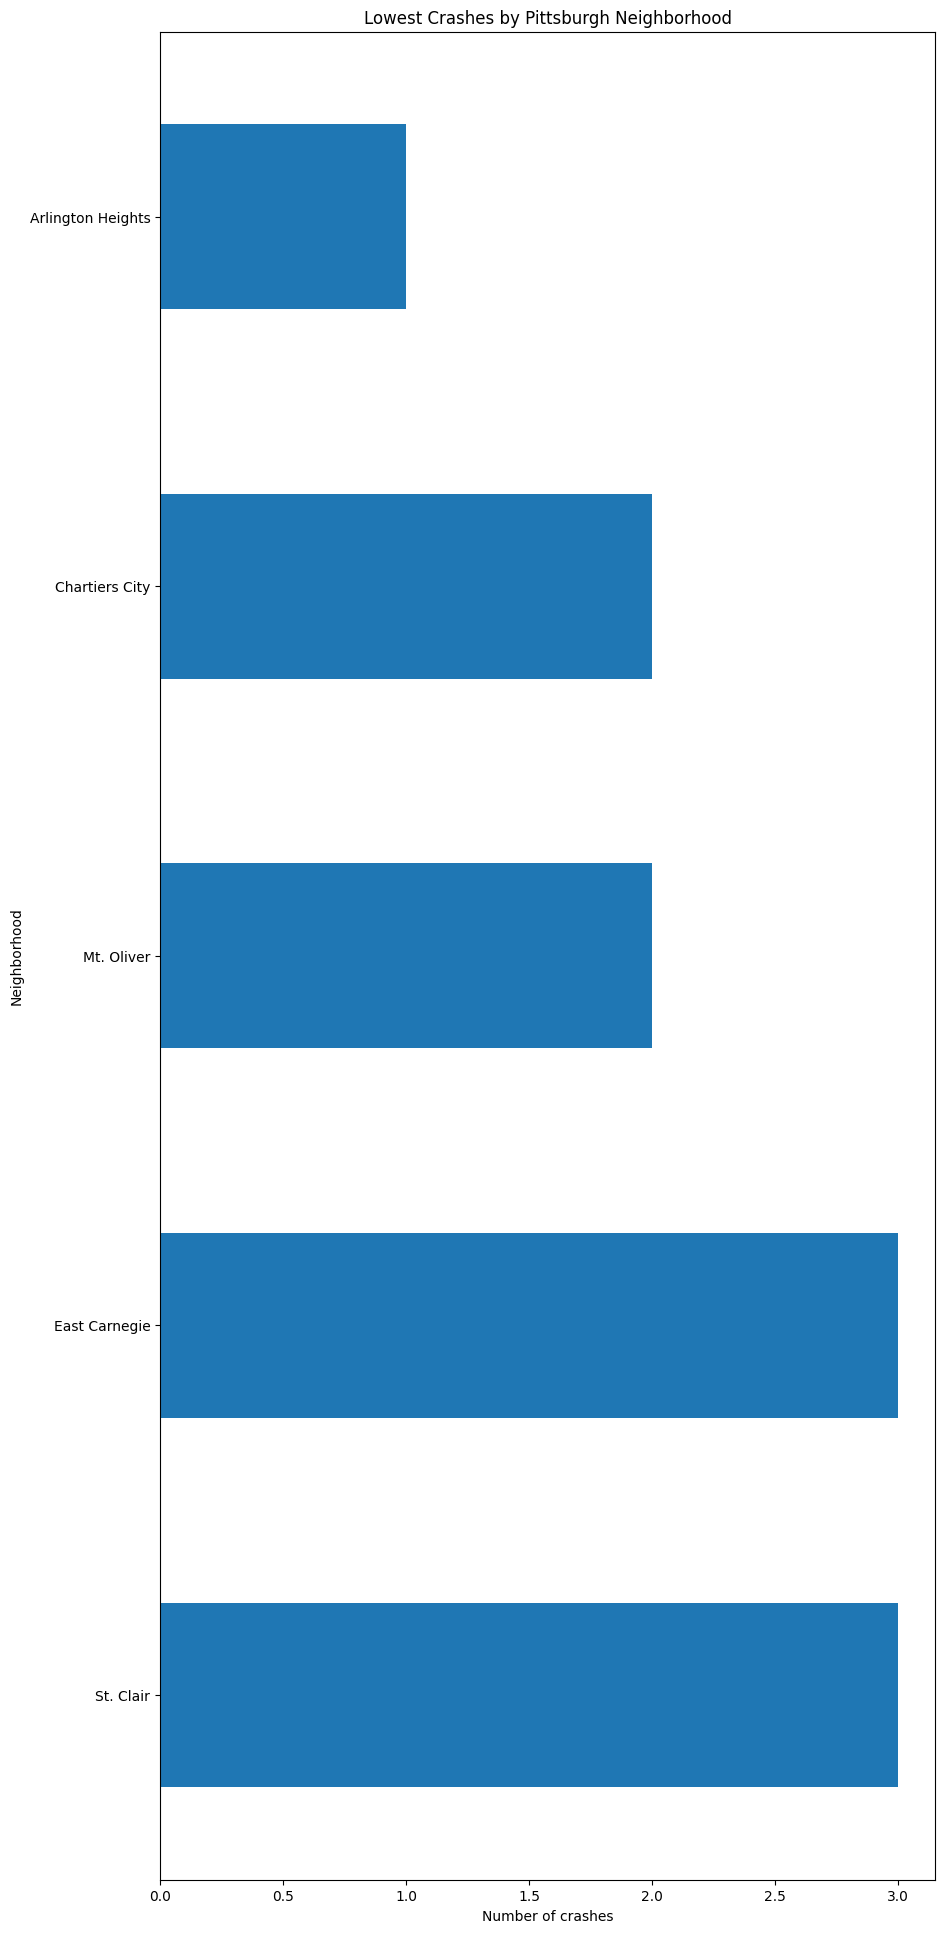

In [20]:
joined["neighborhood"].value_counts().tail(5).plot.barh(
    figsize=(10, 24),
    title="Lowest Crashes by Pittsburgh Neighborhood",
    xlabel="Number of crashes",
    ylabel="Neighborhood",
)